In [2]:
##  Import Important  Libraries 
##  Model Machine بيستحدم ال CPU   
import  numpy as  np
import  pandas as pd 
import matplotlib.pylab as plt 
import seaborn as sns 
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans ## Class  يعتبر يعنى 
from sklearn.metrics import silhouette_score
from sklearn.pipeline import  Pipeline
from sklearn.base  import  BaseEstimator,TransformerMixin

import  joblib

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.max_column',None)
pd.set_option('display.float_format',lambda x:f'{x:,.2f}')
print('Libraries  Load Successfully')


Libraries  Load Successfully


In [3]:
Data_path=pd.read_csv(r'F:\Course AI online\AI\ML\Session  7 -Clustring\archive\online_retail_II.csv')
Data_path

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,"12,680.00",France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,"12,680.00",France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,"12,680.00",France


In [4]:
Data_path.describe(include='all')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
count,1067371,1067371,1062989,"1,067,371.00",1067371,"1,067,371.00","824,364.00",1067371
unique,53628,5305,5698,NaN,47635,NaN,NaN,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,2010-12-06 16:57:00,NaN,NaN,United Kingdom
freq,1350,5829,5918,NaN,1350,NaN,NaN,981330
mean,NaN,NaN,NaN,9.94,NaN,4.65,"15,324.64",NaN
std,NaN,NaN,NaN,172.71,NaN,123.55,"1,697.46",NaN
min,NaN,NaN,NaN,"-80,995.00",NaN,"-53,594.36","12,346.00",NaN
25%,NaN,NaN,NaN,1.00,NaN,1.25,"13,975.00",NaN
50%,NaN,NaN,NaN,3.00,NaN,2.10,"15,255.00",NaN
75%,NaN,NaN,NaN,10.00,NaN,4.15,"16,797.00",NaN


In [5]:
Data_path.describe(include='object')

,Invoice,StockCode,Description,InvoiceDate,Country
count,1067371,1067371,1062989,1067371,1067371
unique,53628,5305,5698,47635,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2010-12-06 16:57:00,United Kingdom
freq,1350,5829,5918,1350,981330


In [6]:
Data_path.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [7]:
Data_path['InvoiceDate'] = pd.to_datetime(Data_path['InvoiceDate'])
Data_path['Customer ID'] = Data_path['Customer ID'].astype('Int64')

In [8]:
Data_path.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   Int64         
 7   Country      1067371 non-null  object        
dtypes: Int64(1), datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 66.2+ MB


In [9]:
Data_path.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [10]:
Data_path['Description'] = Data_path['Description'].fillna('Unknown')

In [11]:
print('Missing Value per column')
missing = Data_path.isnull().sum()
missing_pct = (missing/len(Data_path)*100).round(2)
pd.DataFrame({'missing_count':missing,'missing_pct':missing_pct}).sort_values('missing_count',ascending=True)


Missing Value per column


,missing_count,missing_pct
Invoice,0,0.00
StockCode,0,0.00
Description,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Customer ID,243007,22.77


In [12]:
## Unique() and  nunique()
## Unique  بترجع القيم الفريده ملها 
## nunique() بترجعغ عدد القيم الفريده كلها 
print("Duplication Raw:",Data_path.duplicated().sum())
print("Unique Inovices:",Data_path['Invoice'].nunique())
print("Unique Customers:",Data_path['Customer ID'].nunique())
print("Unique Products(stockcode):",Data_path['StockCode'].nunique())
print("Date range:",Data_path['InvoiceDate'].min(),'to',Data_path['InvoiceDate'].max())
print("Countries:",Data_path['Country'].nunique())

Duplication Raw: 34335
Unique Inovices: 53628
Unique Customers: 5942
Unique Products(stockcode): 5305
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Countries: 43


C:\Users\PC\AppData\Local\Temp\ipykernel_12692\3401004026.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values,y=top_countries.index,palette='viridis')


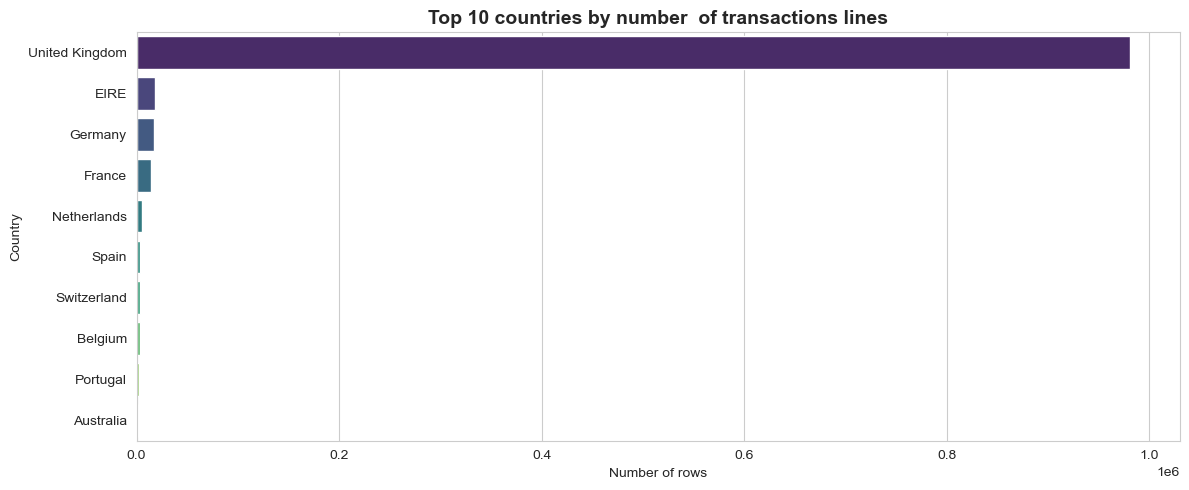

In [13]:
plt.figure(figsize=(12,5))
top_countries = Data_path['Country'].value_counts().head(10)
sns.barplot(x=top_countries.values,y=top_countries.index,palette='viridis')
plt.title("Top 10 countries by number  of transactions lines")
plt.xlabel("Number of rows")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [14]:
Data_path['IsCancelled'] = Data_path['Invoice'].astype(str).str.startswith('C')
print('Canceled Transaction Lines:',Data_path['IsCancelled'].sum())
print(f'percentage of total row: {round(Data_path["IsCancelled"].mean()*100, 2)}%')

print("Quantity State:")
print(Data_path['Quantity'].describe())

print("\n Uniteprice State:")
print(Data_path['Price'].describe())
##  القيمه ال هيا -80  هى قيمه Cancled  محتاج اشيلها 

Canceled Transaction Lines: 19494
percentage of total row: 1.83%
Quantity State:
count   1,067,371.00
mean            9.94
std           172.71
min       -80,995.00
25%             1.00
50%             3.00
75%            10.00
max        80,995.00
Name: Quantity, dtype: float64

 Uniteprice State:
count   1,067,371.00
mean            4.65
std           123.55
min       -53,594.36
25%             1.25
50%             2.10
75%             4.15
max        38,970.00
Name: Price, dtype: float64


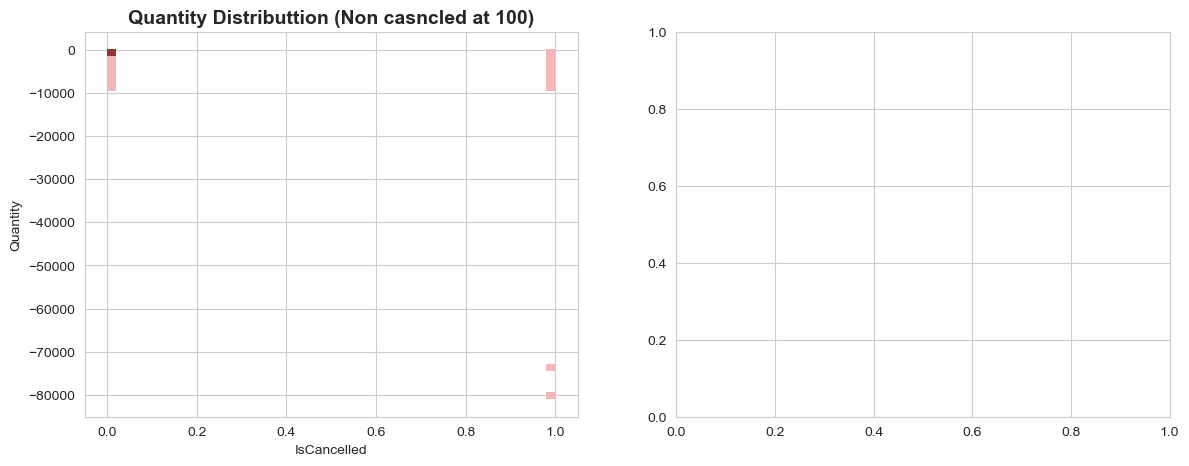

In [15]:
fig,axes  = plt.subplots(1,2,figsize=(14,5))
sns.histplot(x=Data_path['IsCancelled'],y=Data_path['Quantity'].clip(upper=100),bins=50,ax=axes[0],color='red')
axes[0].set_title("Quantity Distributtion (Non casncled at 100)")



plt.tight_layout
plt.show()


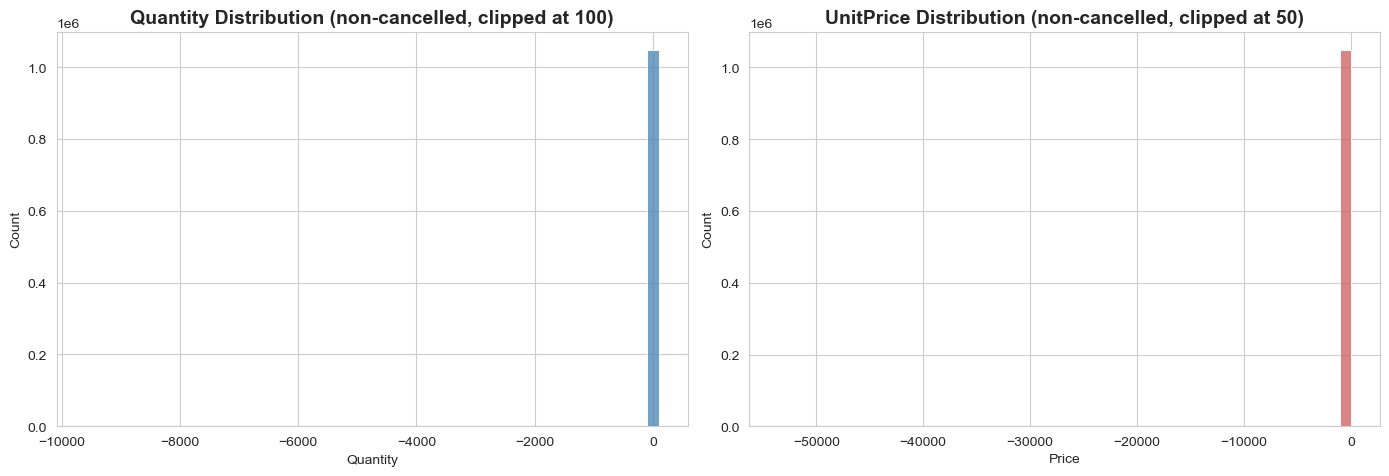

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(Data_path.loc[~Data_path['IsCancelled'], 'Quantity'].clip(upper=100), bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('Quantity Distribution (non-cancelled, clipped at 100)')

sns.histplot(Data_path.loc[~Data_path['IsCancelled'], 'Price'].clip(upper=50), bins=50, ax=axes[1], color='indianred')
axes[1].set_title('UnitPrice Distribution (non-cancelled, clipped at 50)')

plt.tight_layout()
plt.show()

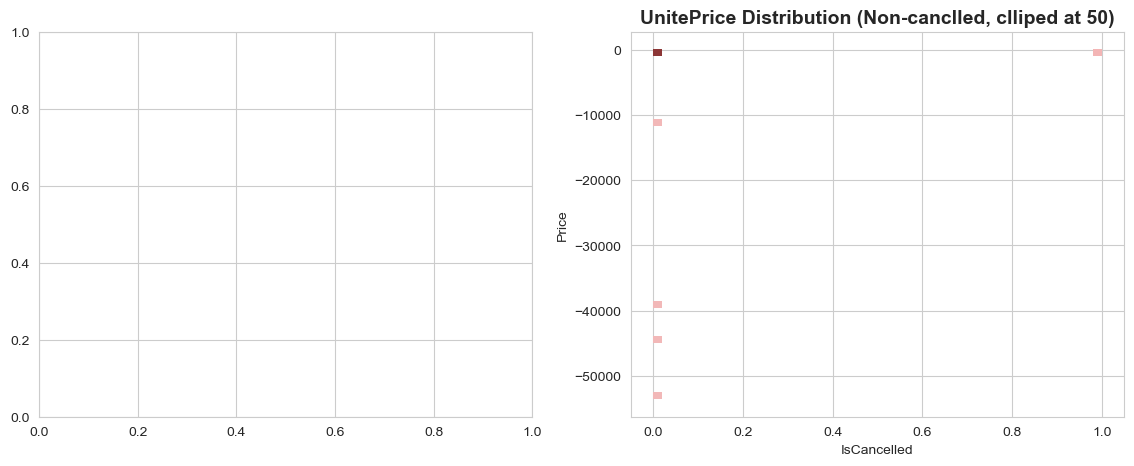

In [17]:
fig,axes  = plt.subplots(1,2,figsize=(14,5))

sns.histplot(x=Data_path['IsCancelled'],y=Data_path['Price'].clip(upper=100),bins=50,ax=axes[1],color='red')
axes[1].set_title("UnitePrice Distribution (Non-canclled, clliped at 50)")

plt.tight_layout
plt.show()

## Data Cleaning¶

Now we make explicit, justified cleaning decisions. An expert never cleans silently — every removal is documented with a reason and a row count, so the work is auditable.

Our cleaning rules:
 Drop rows with missing CustomerID —
 we cannot build a customer profile for an anonymous transaction.
 Drop cancelled orders (InvoiceNo starting with 'C') — 

these represent returns, not purchases, and would distort spending/frequency metrics.
 Drop rows with Quantity <= 0 — 

after removing cancellations, any remaining non-positive quantity is a data anomaly, not a real sale.
 Drop rows with UnitPrice <= 0 —
 zero-price rows are typically manual adjustments/bank fees, not actual products sold.

Drop exact duplicate rows —
 accidental double-entries would inflate a customer's frequency/monetary values.
 Drop rows with missing Description 
— a product we can't name can't be recommended.

# Audit Trail 

In [18]:
print("Starting rows:", len(Data_path))
Data_path_clean = Data_path.copy()

step_log = []

# 1. Missing CustomerID
before = len(Data_path_clean)
Data_path_clean = Data_path_clean.dropna(subset=['Customer ID'])
step_log.append(('Dropped missing CustomerID', before - len(Data_path_clean)))

# 2. Cancelled orders
before = len(Data_path_clean)
Data_path_clean = Data_path_clean[~Data_path_clean['Invoice'].astype(str).str.startswith('C')]
step_log.append(('Dropped cancelled invoices', before - len(Data_path_clean)))

# 3. Non-positive quantity
before = len(Data_path_clean)
Data_path_clean = Data_path_clean[Data_path_clean['Quantity'] > 0]
step_log.append(('Dropped Quantity <= 0', before - len(Data_path_clean)))

# 4. Non-positive price
before = len(Data_path_clean)
Data_path_clean = Data_path_clean[Data_path_clean['Price'] > 0]
step_log.append(('Dropped UnitPrice <= 0', before - len(Data_path_clean)))

# 5. Exact duplicates
before = len(Data_path_clean)
Data_path_clean = Data_path_clean.drop_duplicates()
step_log.append(('Dropped exact duplicate rows', before - len(Data_path_clean)))

# 6. Missing description
before = len(Data_path_clean)
Data_path_clean = Data_path_clean.dropna(subset=['Description'])
step_log.append(('Dropped missing Description', before - len(Data_path_clean)))

Data_path_clean['Customer ID'] = Data_path_clean['Customer ID'].astype(int)

log_df = pd.DataFrame(step_log, columns=['Cleaning Step', 'Rows Removed'])
print(log_df.to_string(index=False))
print("\nFinal cleaned shape:", Data_path_clean.shape)
print("Retained", round(len(Data_path_clean) / len(Data_path_clean) * 100, 1), "% of original rows")

Starting rows: 1067371
               Cleaning Step  Rows Removed
  Dropped missing CustomerID        243007
  Dropped cancelled invoices         18744
       Dropped Quantity <= 0             0
      Dropped UnitPrice <= 0            71
Dropped exact duplicate rows         26124
 Dropped missing Description             0

Final cleaned shape: (779425, 9)
Retained 100.0 % of original rows


In [19]:
type('Customer ID')

str

In [20]:
raw_with_customer = Data_path.dropna(subset=['Customer ID']).copy()
raw_with_customer['Customer ID'] = raw_with_customer['Customer ID'].astype(int)

raw_with_customer['IsCancelled'] = raw_with_customer['Invoice'].astype(str).str.startswith('C')

cancelled_invoices = raw_with_customer.loc[raw_with_customer['IsCancelled']].groupby('Customer ID')['Invoice'].nunique()
total_invoices = raw_with_customer.groupby('Customer ID')['Invoice'].nunique()

return_rate = (cancelled_invoices / total_invoices).fillna(0.0)
return_rate.name = 'ReturnRate'

print("Customers with at least one cancellation:", (cancelled_invoices > 0).sum())
print("Return rate stats:")
print(return_rate.describe().round(3))

Customers with at least one cancellation: 2572
Return rate stats:
count   5,942.00
mean        0.13
std         0.19
min         0.00
25%         0.00
50%         0.00
75%         0.22
max         1.00
Name: ReturnRate, dtype: float64


In [21]:
Data_path_clean['TotalPrice']= Data_path_clean['Quantity'] * Data_path_clean['Price']
Data_path_clean['InvoiceDate'] = pd.to_datetime(Data_path_clean['InvoiceDate'])
Data_path_clean[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'TotalPrice', 'InvoiceDate', 'Customer ID']].head()

,Invoice,StockCode,Description,Quantity,Price,TotalPrice,InvoiceDate,Customer ID
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.40,2009-12-01 07:45:00,13085
1,489434,79323P,PINK CHERRY LIGHTS,12,6.75,81.00,2009-12-01 07:45:00,13085
2,489434,79323W,WHITE CHERRY LIGHTS,12,6.75,81.00,2009-12-01 07:45:00,13085
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,100.80,2009-12-01 07:45:00,13085
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,30.00,2009-12-01 07:45:00,13085


# RMF

In [22]:
snapshot_date =  Data_path_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print('SnapShot Date (our (today))',snapshot_date)
customer_df = Data_path_clean.groupby('Customer ID').agg(
    ## RMF
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
    TotalQuantity=('Quantity', 'sum'),
    UniqueProducts=('StockCode', 'nunique'),
).reset_index()
customer_df['AvgOrderValue'] = (customer_df['Monetary'] / customer_df['Frequency']).round(2)
print("Customer-level table shape:", customer_df.shape)
customer_df.head()

SnapShot Date (our (today)) 2011-12-10 12:50:00
Customer-level table shape: (5878, 7)


,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AvgOrderValue
0,12346,326,12,"77,556.46",74285,27,"6,463.04"
1,12347,2,8,"4,921.53",2967,126,615.19
2,12348,75,5,"2,019.40",2714,25,403.88
3,12349,19,4,"4,428.69",1624,138,"1,107.17"
4,12350,310,1,334.40,197,17,334.40


In [23]:
# 1. حساب إجمالي قطع المشتريات (الكميات الموجبة فقط) لكل عميل
total_purchased = Data_path_clean[Data_path_clean['Quantity'] > 0].groupby('Customer ID')['Quantity'].sum()

# 2. حساب إجمالي قطع المرتجعات (الكميات السالبة وتحويلها لموجب) لكل عميل
total_returned = Data_path_clean[Data_path_clean['Quantity'] < 0].groupby('Customer ID')['Quantity'].sum().abs()

# 3. حساب نسبة المرتجعات وتسمية الناتج ReturnRate
return_rate = (total_returned / total_purchased)
return_rate.name = 'ReturnRate'

# 4. الدمج مع جدول العملاء الرئيسي customer_df
customer_df = customer_df.merge(return_rate.reset_index(), on='Customer ID', how='left')

# 5. استبدال الـ NaN برقم 0 للعملاء اللي معندهمش أي مرتجعات
customer_df['ReturnRate'] = customer_df['ReturnRate'].fillna(0.0)

# 6. عرض عينة للتأكد
customer_df[['Customer ID', 'Frequency', 'Monetary', 'ReturnRate']].head()

,Customer ID,Frequency,Monetary,ReturnRate
0,12346,12,"77,556.46",0.00
1,12347,8,"4,921.53",0.00
2,12348,5,"2,019.40",0.00
3,12349,4,"4,428.69",0.00
4,12350,1,334.40,0.00


In [24]:
customer_df.describe()

,Customer ID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,AvgOrderValue,ReturnRate
count,"5,878.00","5,878.00","5,878.00","5,878.00","5,878.00","5,878.00","5,878.00","5,878.00"
mean,"15,315.31",201.33,6.29,"2,955.90","1,788.70",81.99,385.18,0.00
std,"1,715.57",209.34,13.01,"14,440.85","8,876.30",116.48,"1,214.29",0.00
min,"12,346.00",1.00,1.00,2.95,1.00,1.00,2.95,0.00
25%,"13,833.25",26.00,1.00,342.28,187.00,19.00,176.68,0.00
50%,"15,314.50",96.00,3.00,867.74,480.00,45.00,279.24,0.00
75%,"16,797.75",380.00,7.00,"2,248.30","1,350.00",103.00,414.90,0.00
max,"18,287.00",739.00,398.00,"580,987.04","367,193.00","2,550.00","84,236.25",0.00


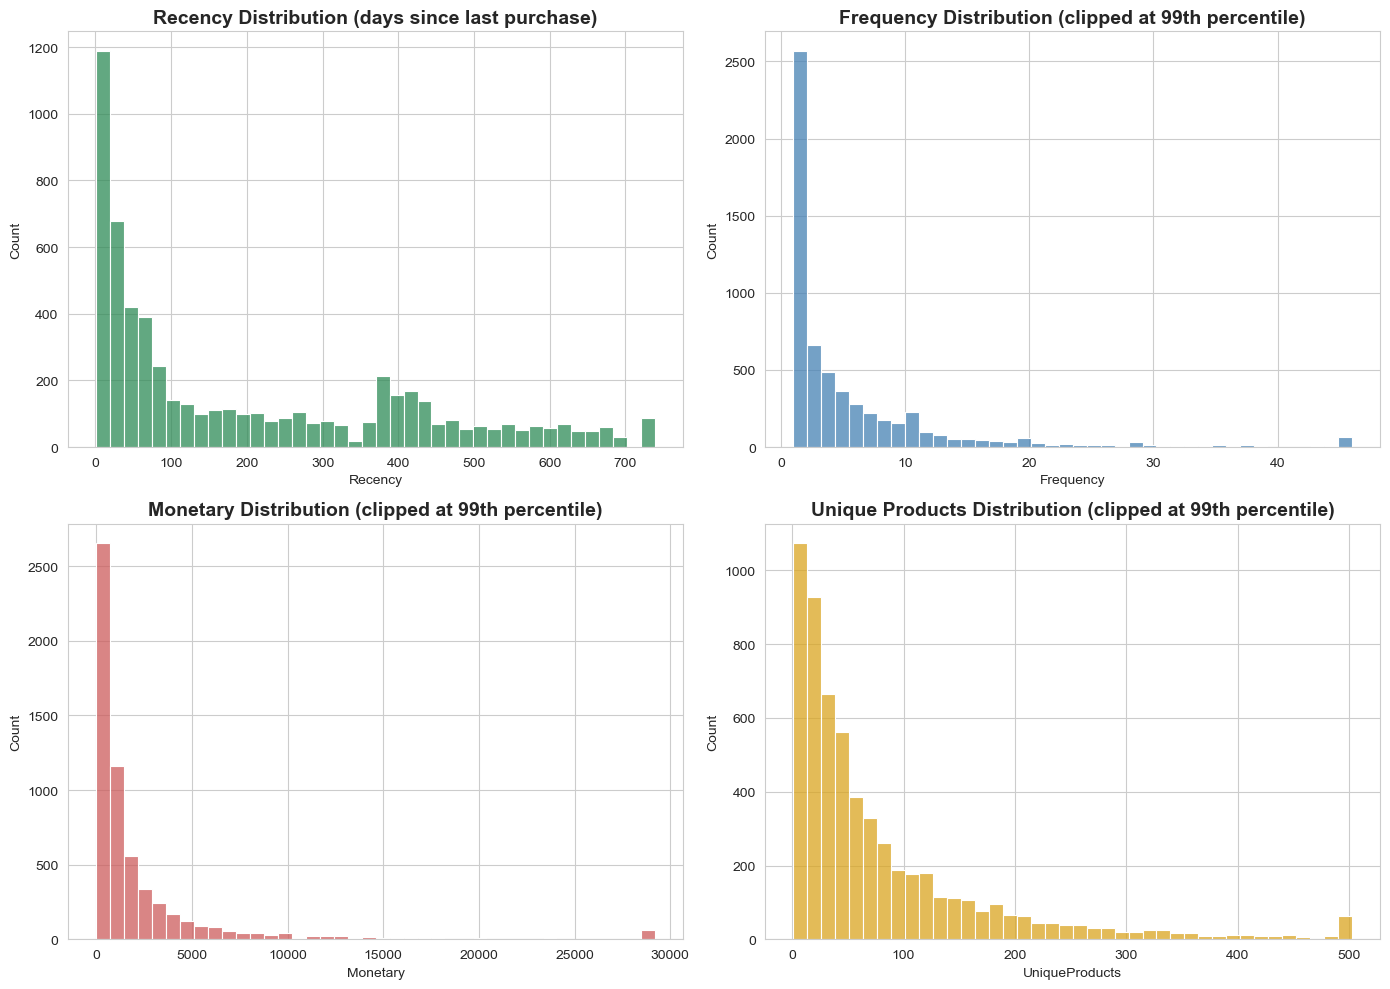

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(customer_df['Recency'], bins=40, ax=axes[0,0], color='seagreen')
axes[0,0].set_title('Recency Distribution (days since last purchase)')

sns.histplot(customer_df['Frequency'].clip(upper=customer_df['Frequency'].quantile(0.99)),
             bins=40, ax=axes[0,1], color='steelblue')
axes[0,1].set_title('Frequency Distribution (clipped at 99th percentile)')

sns.histplot(customer_df['Monetary'].clip(upper=customer_df['Monetary'].quantile(0.99)),
             bins=40, ax=axes[1,0], color='indianred')
axes[1,0].set_title('Monetary Distribution (clipped at 99th percentile)')

sns.histplot(customer_df['UniqueProducts'].clip(upper=customer_df['UniqueProducts'].quantile(0.99)),
             bins=40, ax=axes[1,1], color='goldenrod')
axes[1,1].set_title('Unique Products Distribution (clipped at 99th percentile)')

plt.tight_layout()
plt.show()

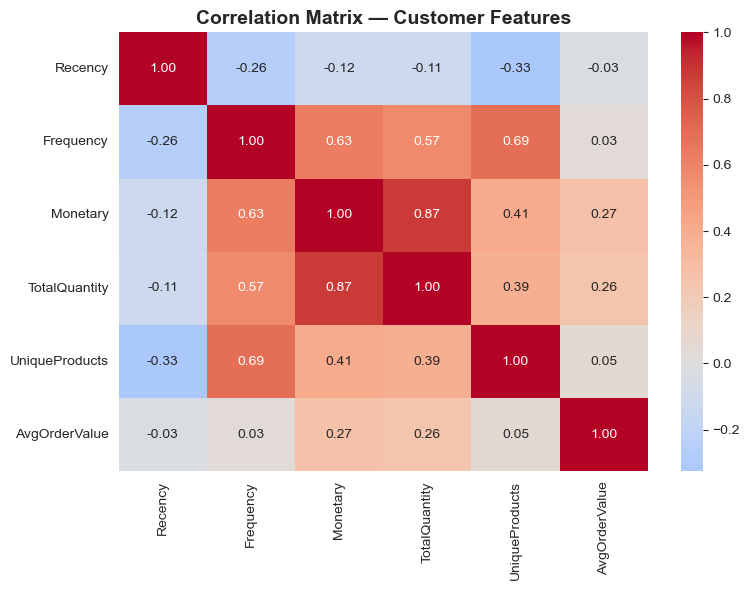

In [26]:
plt.figure(figsize=(8, 6))
corr = customer_df[['Recency','Frequency','Monetary','TotalQuantity','UniqueProducts','AvgOrderValue']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Matrix — Customer Features')
plt.tight_layout()
plt.show()


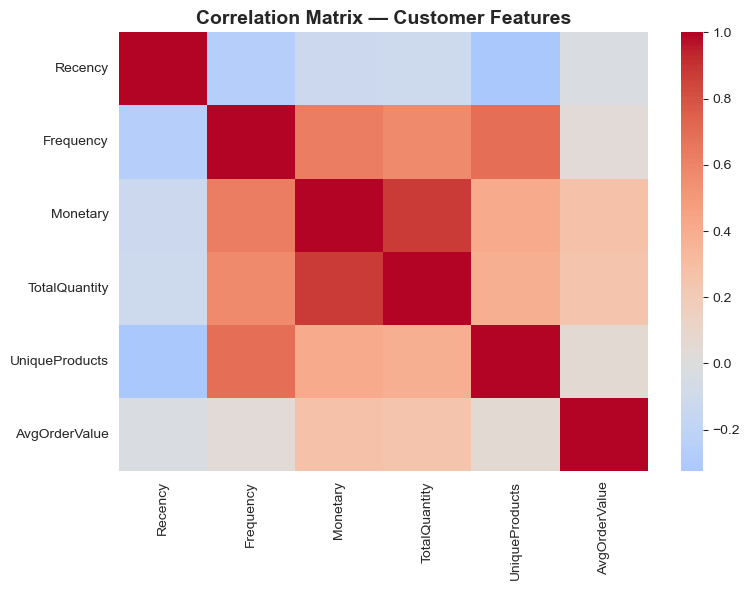

In [27]:
plt.figure(figsize=(8, 6))
corr = customer_df[['Recency','Frequency','Monetary','TotalQuantity','UniqueProducts','AvgOrderValue']].corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', fmt='.2f', center=0)
plt.title('Correlation Matrix — Customer Features')
plt.tight_layout()
plt.show()

## annot = False  مش بيجبلك الارقام 
## annot = True  بيجبلك الارقام عادى 

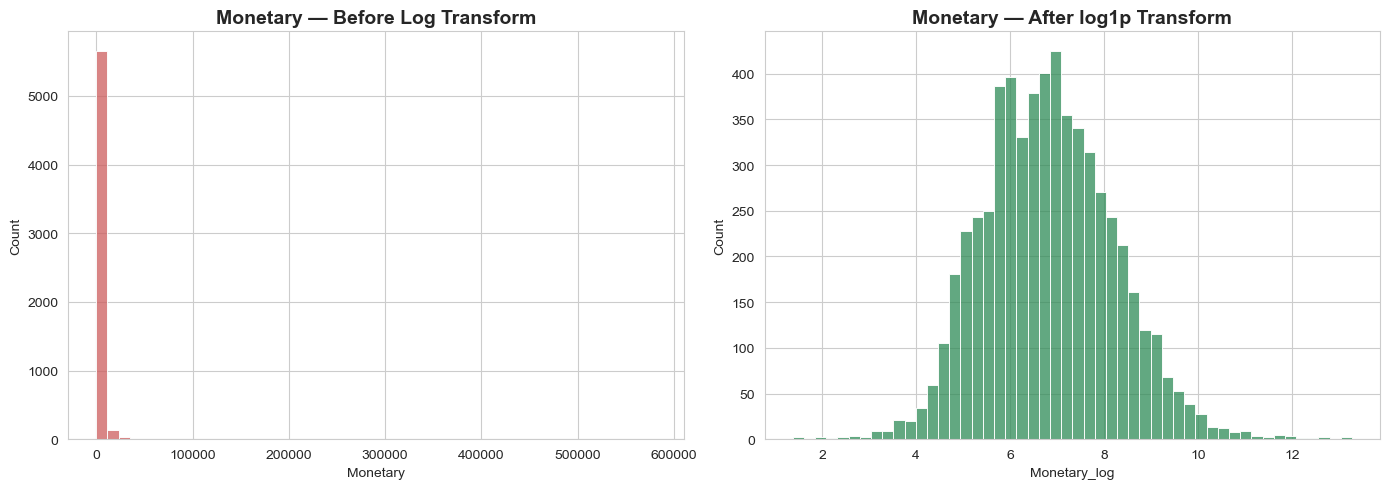

In [28]:
## علشان اعالج مشكله ال Skewwed   For Data 
for col in ['Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'AvgOrderValue']:
    customer_df[f'{col}_log'] = np.log1p(customer_df[col].clip(lower=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(customer_df['Monetary'], bins=50, ax=axes[0], color='indianred')
axes[0].set_title('Monetary — Before Log Transform')
sns.histplot(customer_df['Monetary_log'], bins=50, ax=axes[1], color='seagreen')
axes[1].set_title('Monetary — After log1p Transform')
plt.tight_layout()
plt.show()

In [29]:
FEATURES = ['Recency', 'Frequency_log', 'Monetary_log', 'UniqueProducts_log', 'AvgOrderValue_log']

X = customer_df[FEATURES].copy() ## تاحد منها نسخه وتريح دماغك 

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
##  داله ال Fit_transform  ديما بترجع عل هيئه Array  فلازم احولها ل DataFrame

X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)
X_scaled_df


,Recency,Frequency_log,Monetary_log,UniqueProducts_log,AvgOrderValue_log
0,0.60,1.25,3.21,-0.35,4.29
1,-0.95,0.80,1.22,0.89,1.10
2,-0.60,0.30,0.57,-0.41,0.53
3,-0.87,0.07,1.14,0.96,1.89
4,0.52,-1.06,-0.72,-0.71,0.27
...,...,...,...,...,...
5873,-0.94,1.96,0.77,1.73,-1.10
5874,1.10,-1.06,-0.49,-0.32,0.71
5875,2.20,-1.06,-0.55,-0.98,0.60
5876,1.32,-0.56,0.25,0.38,1.17


In [30]:
FEATURES = ['Recency', 'Frequency_log', 'Monetary_log', 'UniqueProducts_log', 'AvgOrderValue_log']
X = customer_df[FEATURES].copy() ## تاحد منها نسخه وتريح دماغك 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
##  داله ال Fit_transform  ديما بترجع عل هيئه Array  فلازم احولها ل DataFrame

#------------------------------------------------------------------------------------------------------------------#
#------------------------------------------------------------------------------------------------------------------#
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)
print("Scaled feature means (should be ~0):")
print(X_scaled_df.mean().round(3))
print("\nScaled feature std devs (should be ~1):")
print(X_scaled_df.std().round(3))
X_scaled_df.head()



Scaled feature means (should be ~0):
Recency              -0.00
Frequency_log         0.00
Monetary_log          0.00
UniqueProducts_log   -0.00
AvgOrderValue_log    -0.00
dtype: float64

Scaled feature std devs (should be ~1):
Recency              1.00
Frequency_log        1.00
Monetary_log         1.00
UniqueProducts_log   1.00
AvgOrderValue_log    1.00
dtype: float64


,Recency,Frequency_log,Monetary_log,UniqueProducts_log,AvgOrderValue_log
0,0.60,1.25,3.21,-0.35,4.29
1,-0.95,0.80,1.22,0.89,1.10
2,-0.60,0.30,0.57,-0.41,0.53
3,-0.87,0.07,1.14,0.96,1.89
4,0.52,-1.06,-0.72,-0.71,0.27


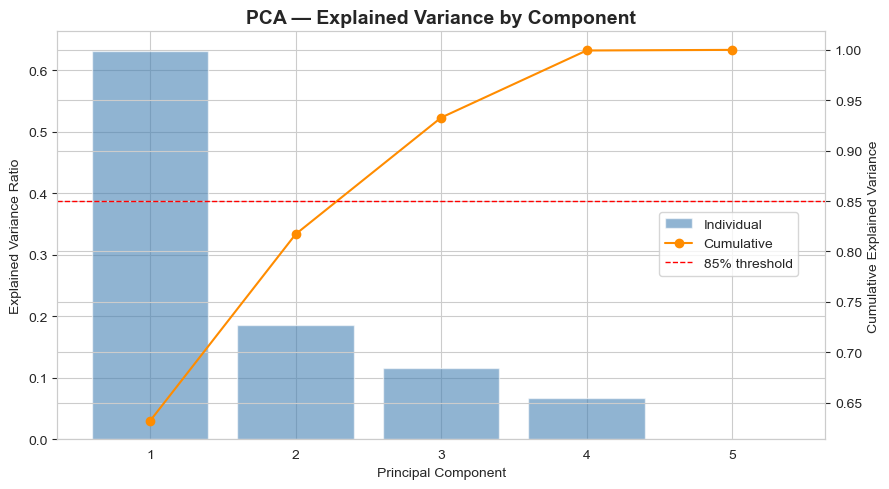

PC1: explains 63.2% individually, 63.2% cumulative
PC2: explains 18.5% individually, 81.7% cumulative
PC3: explains 11.6% individually, 93.3% cumulative
PC4: explains 6.7% individually, 99.9% cumulative
PC5: explains 0.1% individually, 100.0% cumulative


In [33]:
pca_full = PCA(n_components=len(FEATURES), random_state=42)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(range(1, len(explained)+1), explained, alpha=0.6, color='steelblue', label='Individual')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Explained Variance Ratio')

ax2 = ax1.twinx()
ax2.plot(range(1, len(cumulative)+1), cumulative, color='darkorange', marker='o', label='Cumulative')
ax2.set_ylabel('Cumulative Explained Variance')
ax2.axhline(0.85, color='red', linestyle='--', linewidth=1, label='85% threshold')

fig.legend(loc='center right', bbox_to_anchor=(0.9, 0.5))
plt.title('PCA — Explained Variance by Component')
plt.tight_layout()
plt.show()

for i, (e, c) in enumerate(zip(explained, cumulative), start=1):
    print(f"PC{i}: explains {e*100:.1f}% individually, {c*100:.1f}% cumulative")
